# Sales Forecasting System
**Sqrock IT Solutions — Data Science Internship, Phase 1, Task 1**

**Goal:** analyse historical sales and forecast future monthly sales so a business can plan inventory, revenue and staffing.

**Dataset:** *Superstore Sales*: 8,399 real order lines from 2009-2012 with order date, sales amount, product category, region and customer segment.

**Pipeline:** Data collection → Cleaning → EDA → Feature engineering → Models (Linear Regression, Decision Tree, Random Forest, ARIMA) → Prediction → Evaluation (MAE, RMSE)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
pd.options.display.float_format = "{:,.2f}".format

## 1. Data collection

In [2]:
df = pd.read_csv("data/superstore_sales.csv", encoding="latin-1")
print(df.shape)
df.head()

(8399, 21)


,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,"10,123.02",0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483,7/10/2011,High,30,"4,965.76",0.08,Regular Air,"1,198.97",195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515,8/28/2010,Not Specified,19,394.27,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   str    
 3   Order Priority        8399 non-null   str    
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   str    
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   str    
 12  Province              8399 non-null   str    
 13  Region                8399 non-null   str    
 14  Customer Segment      8399 non-null   str    
 15  Product Category      8399 non-n

## 2. Data cleaning
- Convert `Order Date` and `Ship Date` to real datetimes
- Check for and remove duplicate rows
- Handle missing values (`Product Base Margin` has a few gaps, so I fill them with the median of the product's sub-category)

In [4]:
print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
 Product Base Margin    63
dtype: int64

Duplicate rows: 0


In [5]:
df = df.drop_duplicates()
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Product Base Margin"] = df.groupby("Product Sub-Category")["Product Base Margin"] \
    .transform(lambda s: s.fillna(s.median()))
df = df.sort_values("Order Date").reset_index(drop=True)

print("Remaining missing values:", int(df.isna().sum().sum()))
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Remaining missing values: 0
Date range: 2009-01-01 to 2012-12-30


## 3. Exploratory Data Analysis
### 3.1 Sales trend over time

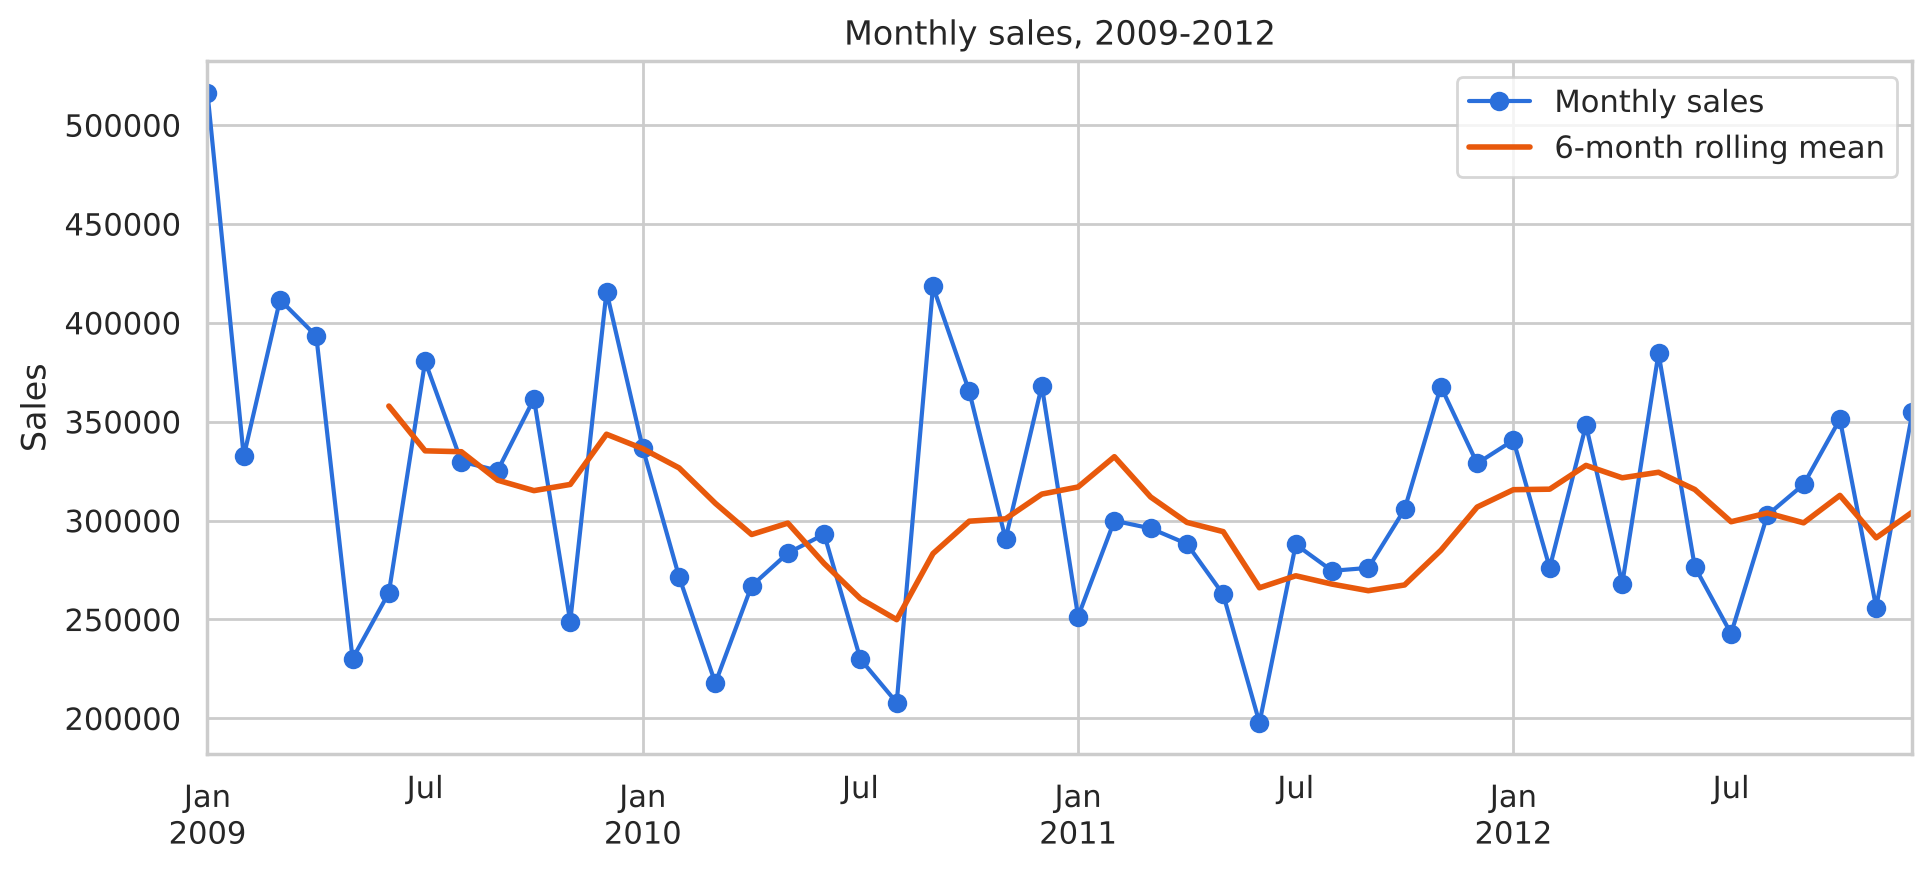

In [6]:
monthly = df.set_index("Order Date")["Sales"].resample("MS").sum()

ax = monthly.plot(marker="o", color="#2a6fdb")
monthly.rolling(6).mean().plot(ax=ax, color="#e8590c", lw=2, label="6-month rolling mean")
ax.set(title="Monthly sales, 2009-2012", xlabel="", ylabel="Sales")
ax.legend(["Monthly sales", "6-month rolling mean"])
plt.show()

### 3.2 Highest and lowest sales months

In [7]:
top = monthly.sort_values(ascending=False)
print("Top 5 months:\n", top.head().to_string())
print("\nBottom 5 months:\n", top.tail().to_string())

Top 5 months:
 Order Date
2009-01-01   516,302.96
2010-09-01   418,343.28
2009-12-01   415,809.35
2009-03-01   411,628.73
2009-04-01   393,276.48

Bottom 5 months:
 Order Date
2009-05-01   230,145.54
2010-07-01   229,885.50
2010-03-01   217,808.01
2010-08-01   207,937.01
2011-06-01   197,740.85


### 3.3 Seasonal patterns
Averaging every January, every February and so on shows which months are usually strong.

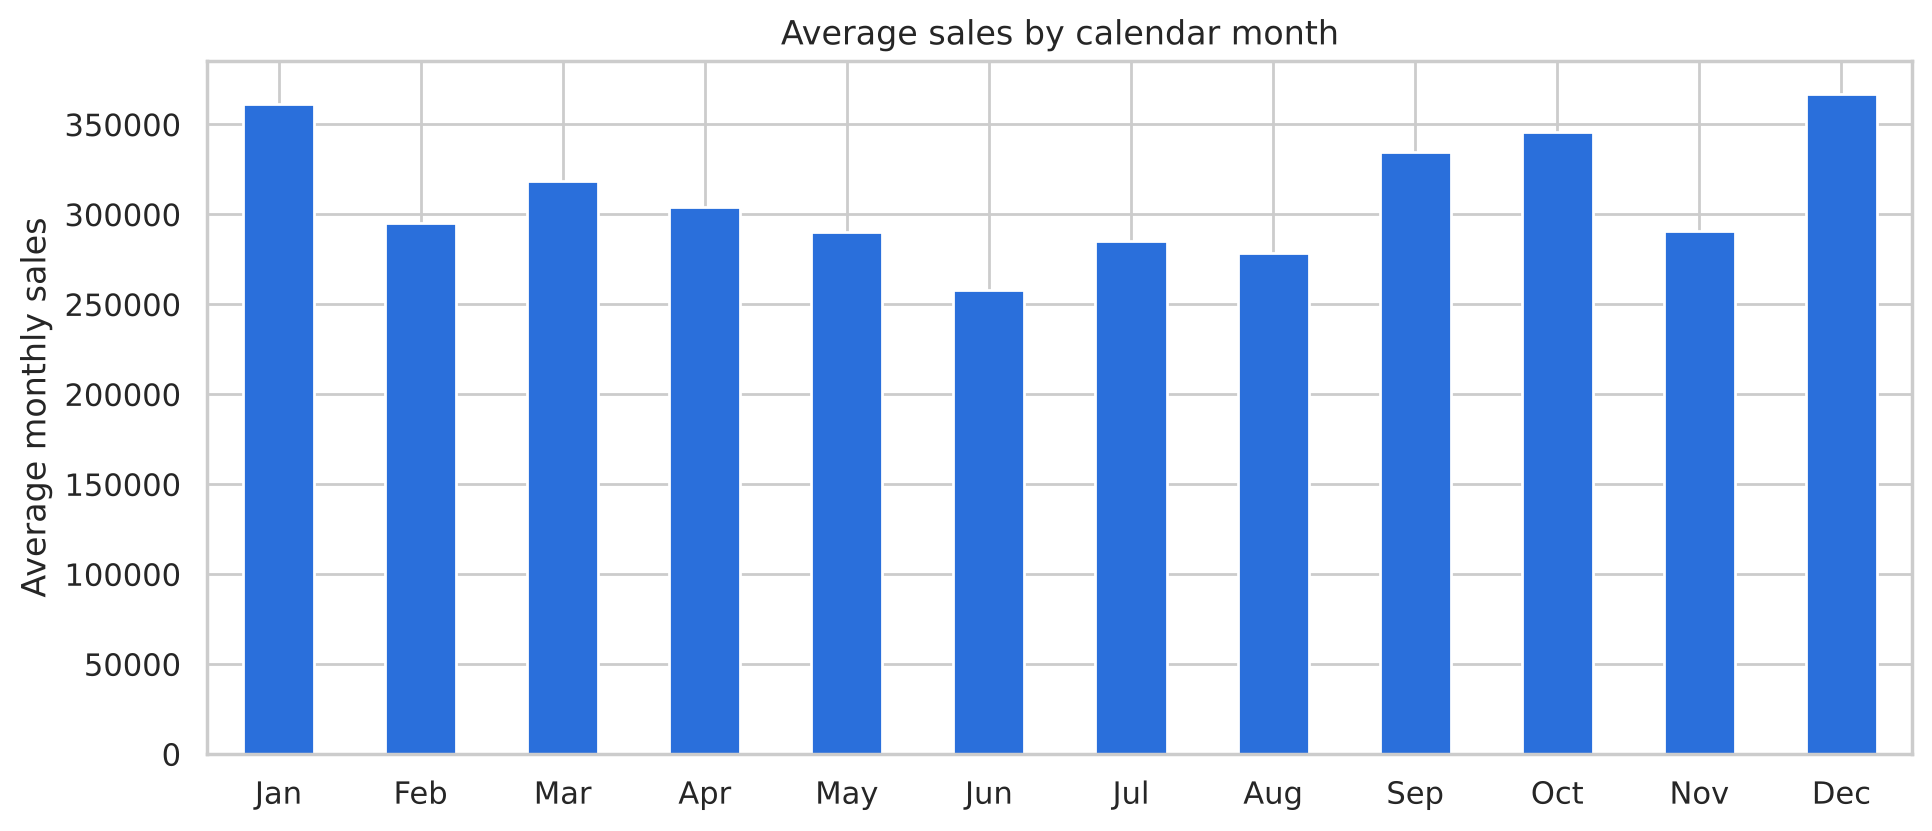

In [8]:
season = monthly.groupby(monthly.index.month).mean()
season.index = pd.to_datetime(season.index, format="%m").strftime("%b")
ax = season.plot(kind="bar", color="#2a6fdb")
ax.set(title="Average sales by calendar month", xlabel="", ylabel="Average monthly sales")
plt.xticks(rotation=0)
plt.show()

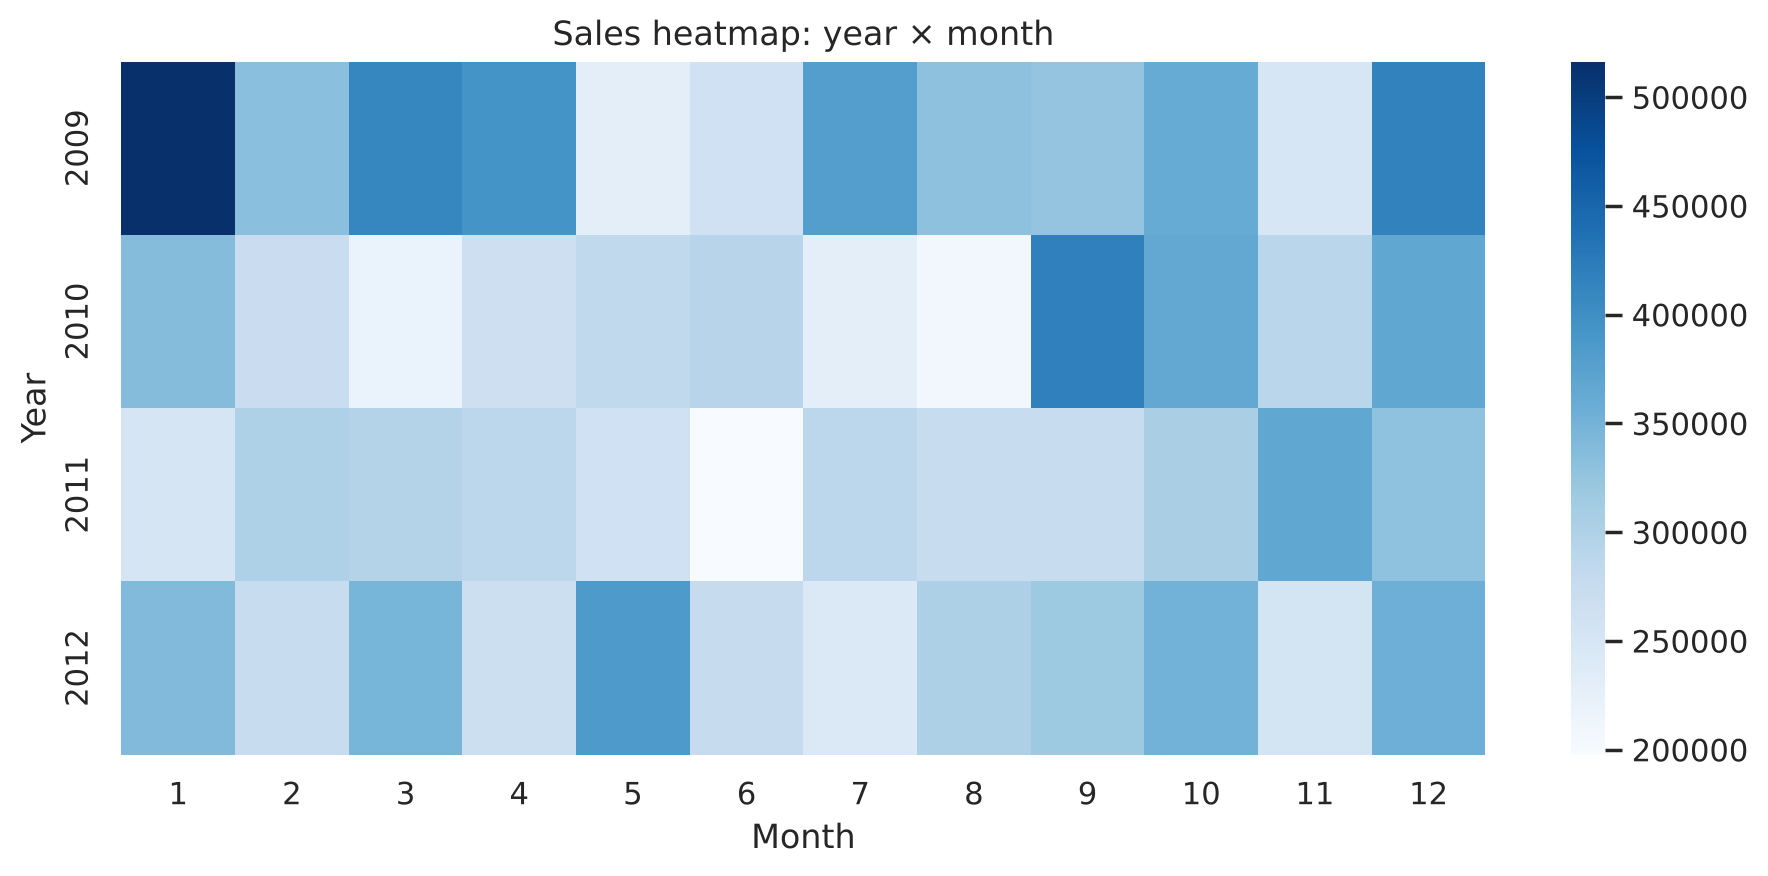

In [9]:
yearly = monthly.to_frame("Sales")
yearly["Year"], yearly["Month"] = yearly.index.year, yearly.index.month
sns.heatmap(yearly.pivot(index="Year", columns="Month", values="Sales"), cmap="Blues", fmt=",.0f")
plt.title("Sales heatmap: year × month")
plt.show()

### 3.4 Sales by category and region

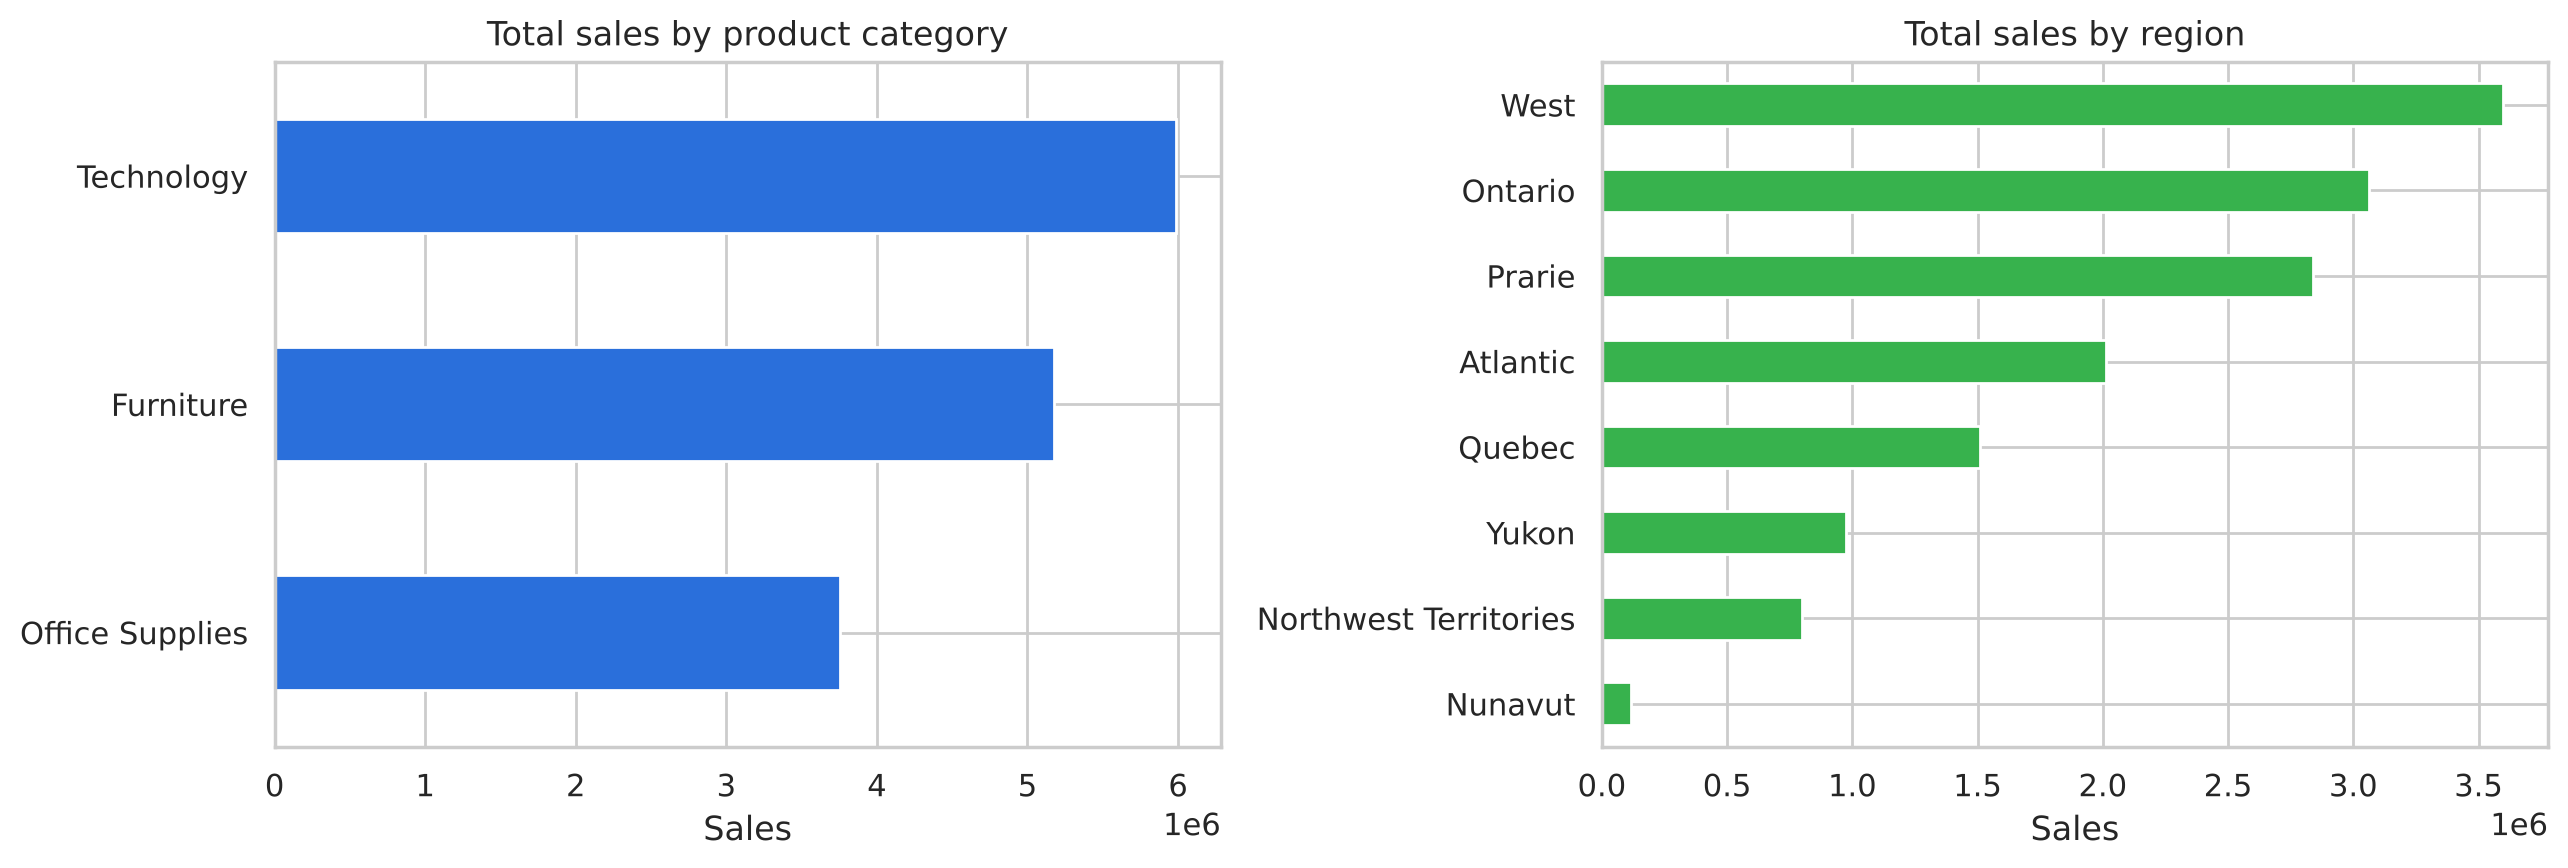

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df.groupby("Product Category")["Sales"].sum().sort_values().plot(kind="barh", ax=axes[0], color="#2a6fdb")
axes[0].set(title="Total sales by product category", xlabel="Sales", ylabel="")
df.groupby("Region")["Sales"].sum().sort_values().plot(kind="barh", ax=axes[1], color="#37b24d")
axes[1].set(title="Total sales by region", xlabel="Sales", ylabel="")
plt.tight_layout()
plt.show()

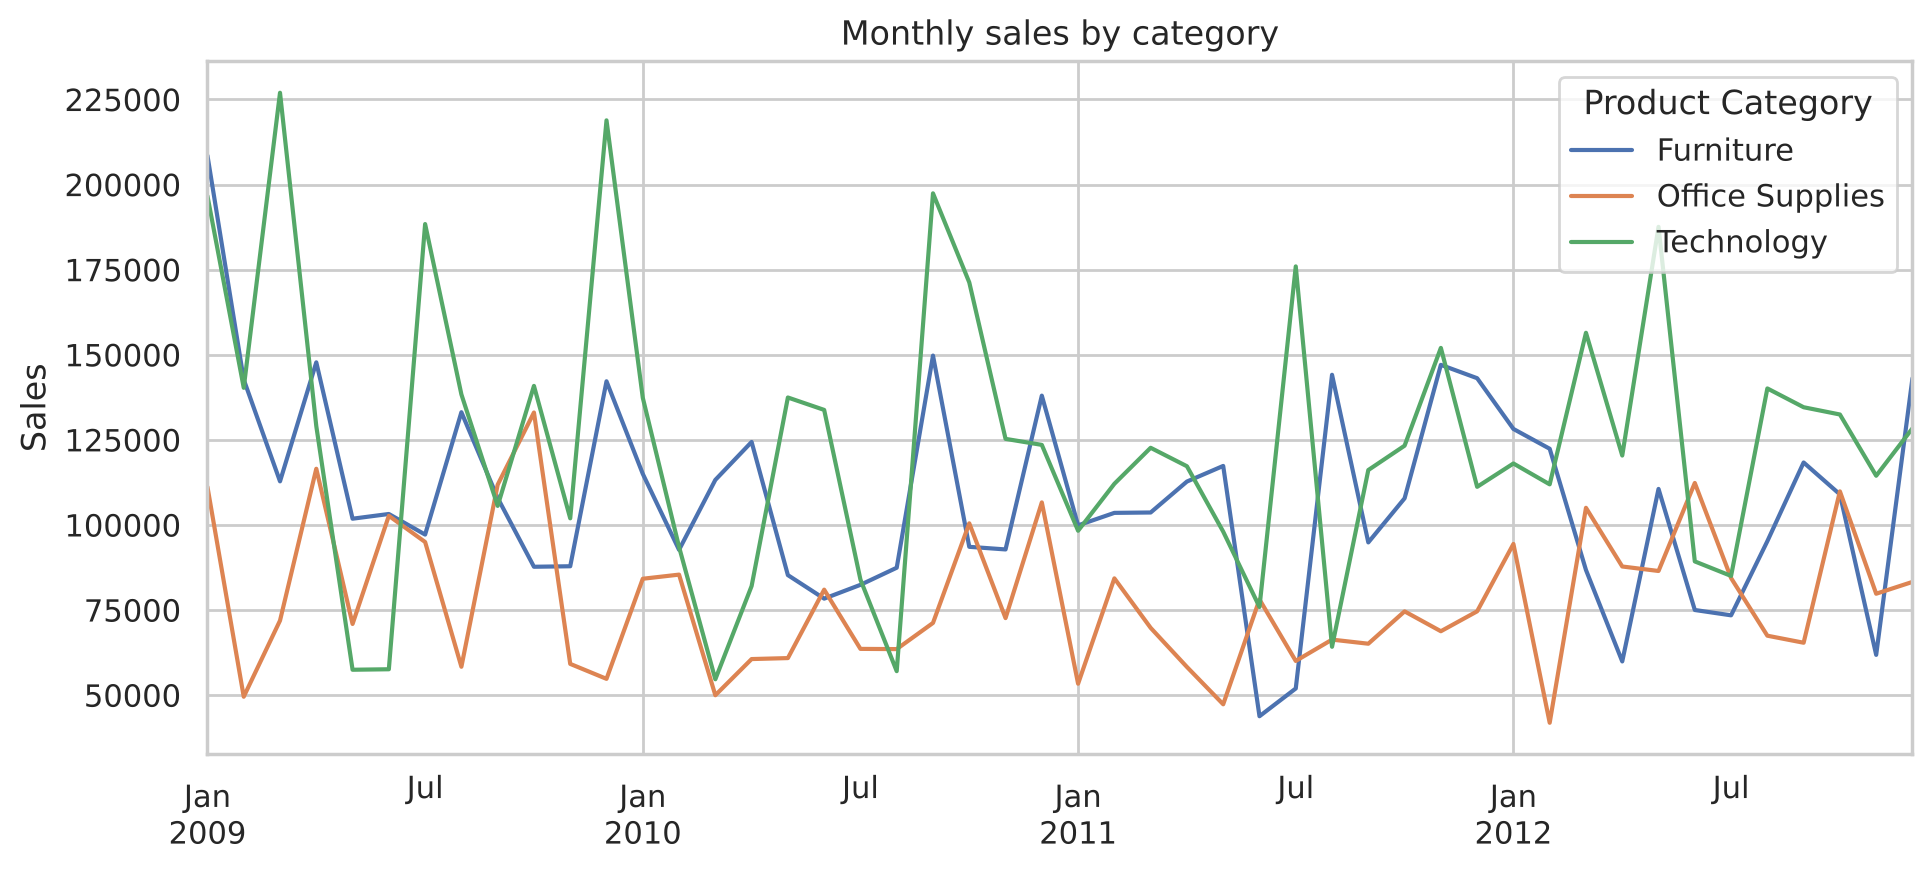

In [11]:
cat_monthly = df.pivot_table(index=pd.Grouper(key="Order Date", freq="MS"),
                             columns="Product Category", values="Sales", aggfunc="sum")
cat_monthly.plot(title="Monthly sales by category", ylabel="Sales", xlabel="")
plt.show()

**EDA takeaways**
- Sales are volatile from month to month, but the rolling mean is fairly flat, so there's no strong growth trend.
- Technology and Furniture bring in most of the revenue. Office Supplies has the most orders but the smallest order values.
- Some calendar months are reliably stronger than others, so month and lag-12 (same month last year) features should help.

## 4. Feature engineering
I forecast **total monthly sales**. For each month I build:
- **Calendar features:** month, year, quarter, days in the month
- **Lag features:** sales 1, 2 and 3 months ago, and 12 months ago (same month last year)
- **Rolling features:** mean of the previous 3 months and previous 6 months

Every lag and rolling feature only uses past values, so the model never sees the month it is predicting.

In [12]:
def make_features(series: pd.Series) -> pd.DataFrame:
    f = pd.DataFrame({"Sales": series})
    f["Month"] = f.index.month
    f["Year"] = f.index.year
    f["Quarter"] = f.index.quarter
    f["DaysInMonth"] = f.index.days_in_month
    for lag in (1, 2, 3, 12):
        f[f"Lag_{lag}"] = f["Sales"].shift(lag)
    f["Rolling_3"] = f["Sales"].shift(1).rolling(3).mean()
    f["Rolling_6"] = f["Sales"].shift(1).rolling(6).mean()
    return f

features = make_features(monthly).dropna()
FEATURES = [c for c in features.columns if c != "Sales"]
features.head()

,Sales,Month,Year,Quarter,DaysInMonth,Lag_1,Lag_2,Lag_3,Lag_12,Rolling_3,Rolling_6
Order Date,,,,,,,,,,,
2010-01-01,"336,526.68",1,2010,1,31,"415,809.35","248,933.43","361,555.27","516,302.96","342,099.35","343,641.51"
2010-02-01,"271,580.51",2,2010,1,28,"336,526.68","415,809.35","248,933.43","332,480.64","333,756.49","336,311.96"
2010-03-01,"217,808.01",3,2010,1,31,"271,580.51","336,526.68","415,809.35","411,628.73","341,305.51","326,616.26"
2010-04-01,"266,968.59",4,2010,2,30,"217,808.01","271,580.51","336,526.68","393,276.48","275,305.07","308,702.21"
2010-05-01,"283,534.28",5,2010,2,31,"266,968.59","217,808.01","271,580.51","230,145.54","252,119.03","292,937.76"


**Train/test split:** time series must be split by time, not at random. The **last 12 months (2012)** are held out as the test set.

In [13]:
TEST_MONTHS = 12
train, test = features.iloc[:-TEST_MONTHS], features.iloc[-TEST_MONTHS:]
X_train, y_train = train[FEATURES], train["Sales"]
X_test, y_test = test[FEATURES], test["Sales"]
print(f"Train: {train.index.min():%b %Y} – {train.index.max():%b %Y} ({len(train)} months)")
print(f"Test:  {test.index.min():%b %Y} – {test.index.max():%b %Y} ({len(test)} months)")

Train: Jan 2010 – Dec 2011 (24 months)
Test:  Jan 2012 – Dec 2012 (12 months)


## 5. Model building
I compare three scikit-learn regressors and an ARIMA time-series model against a **naive baseline** that predicts last month's sales. Any useful model has to beat the baseline.

In [14]:
def evaluate(name, actual, pred):
    return {"Model": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred))}

predictions = {"Naive (last month)": test["Lag_1"].values}

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# ARIMA with a yearly seasonal AR term, fitted on the raw monthly series
arima = ARIMA(monthly.loc[:train.index.max()], order=(1, 0, 1), seasonal_order=(1, 0, 0, 12)).fit()
predictions["ARIMA (1,0,1)(1,0,0,12)"] = arima.forecast(TEST_MONTHS).values

## 6. Evaluation: MAE and RMSE
- **MAE** is the average absolute error, in sales units.
- **RMSE** punishes large misses more heavily than MAE.

In [15]:
results = pd.DataFrame([evaluate(n, y_test, p) for n, p in predictions.items()]).set_index("Model")
baseline_mae = results.loc["Naive (last month)", "MAE"]
results["MAE vs baseline"] = (1 - results["MAE"] / baseline_mae).map("{:+.0%}".format)
results["MAPE"] = [np.mean(np.abs((y_test - p) / y_test)) for p in predictions.values()]
results["MAPE"] = results["MAPE"].map("{:.1%}".format)
results.sort_values("MAE")

,MAE,RMSE,MAE vs baseline,MAPE
Model,,,,
"ARIMA (1,0,1)(1,0,0,12)","39,600.26","44,383.49",+40%,13.1%
Random Forest,"41,751.04","54,049.41",+37%,12.9%
Decision Tree,"47,459.62","58,550.29",+28%,15.5%
Naive (last month),"65,766.39","74,186.23",+0%,21.6%
Linear Regression,"101,748.63","119,620.83",-55%,32.1%


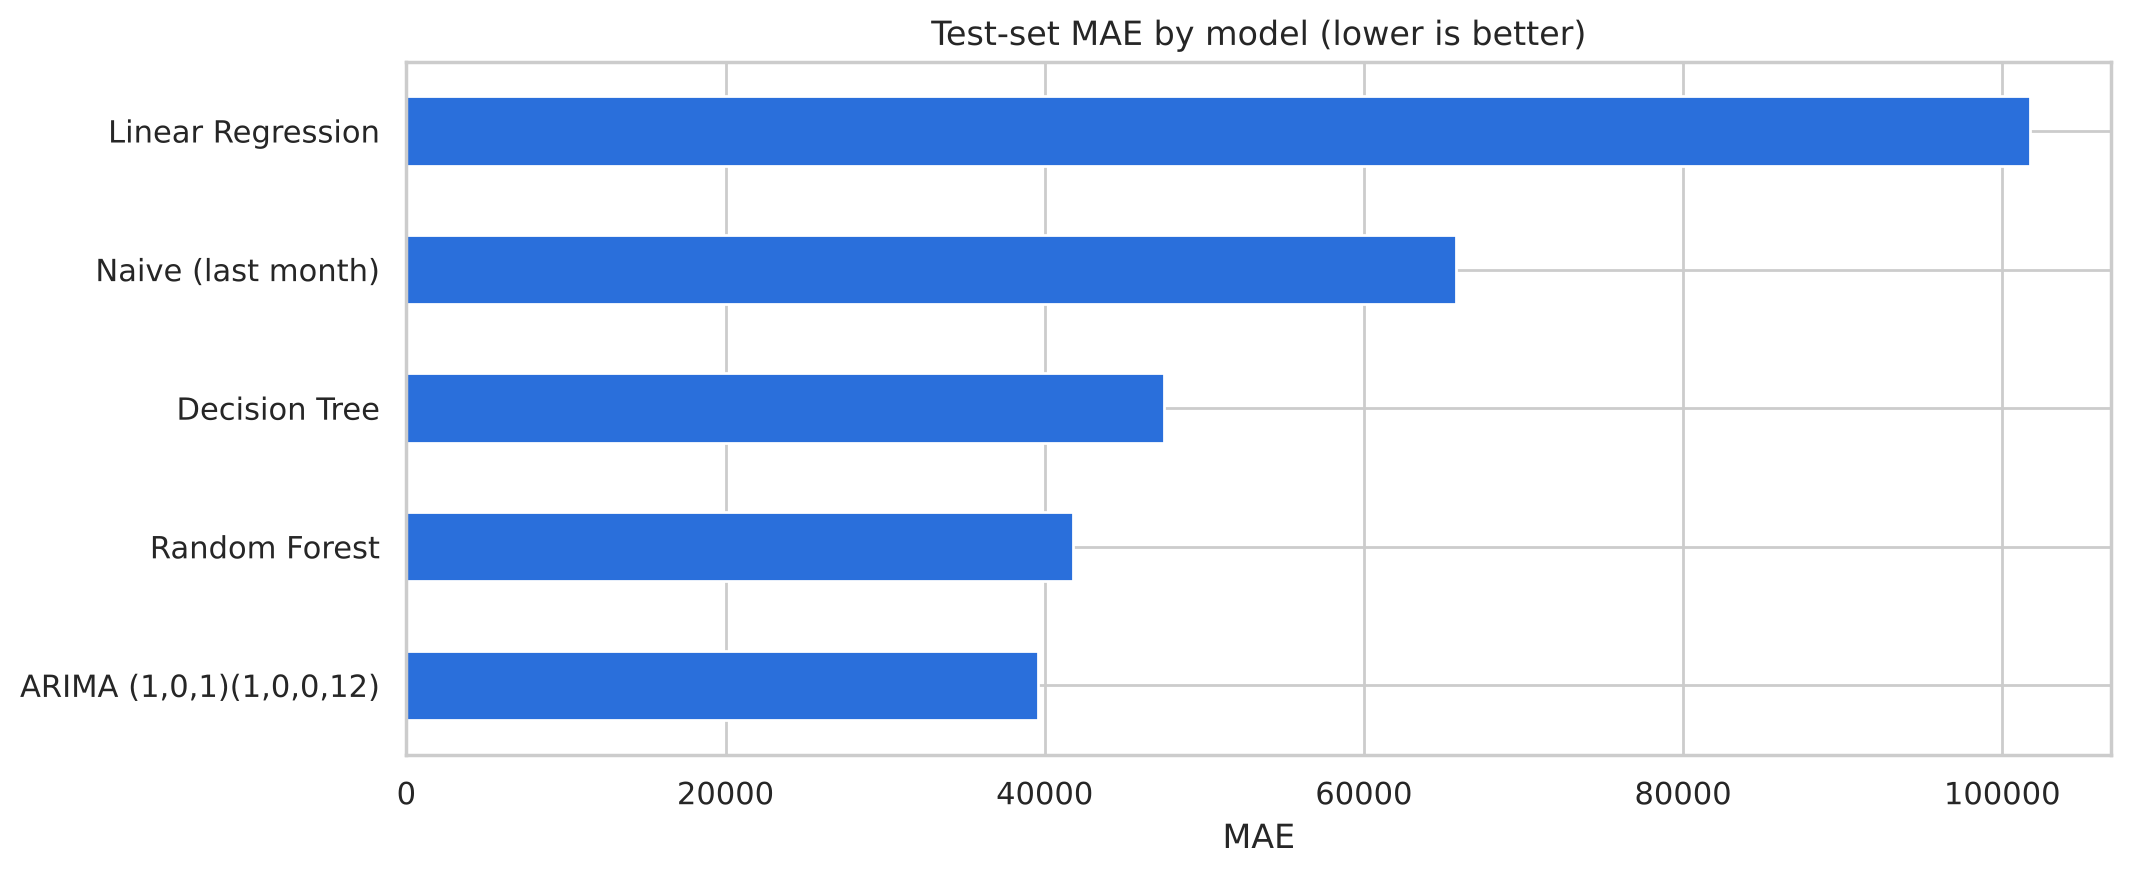

In [16]:
ax = results["MAE"].sort_values().plot(kind="barh", color="#2a6fdb")
ax.set(title="Test-set MAE by model (lower is better)", xlabel="MAE", ylabel="")
plt.show()

**Why does Linear Regression lose?** With only 24 training months and 10 correlated features (the lags and rolling means overlap heavily), the linear model overfits the training years and extrapolates badly. Random Forest and ARIMA handle this small, noisy series much better.

## 7. Prediction: actual vs predicted (2012 test year)

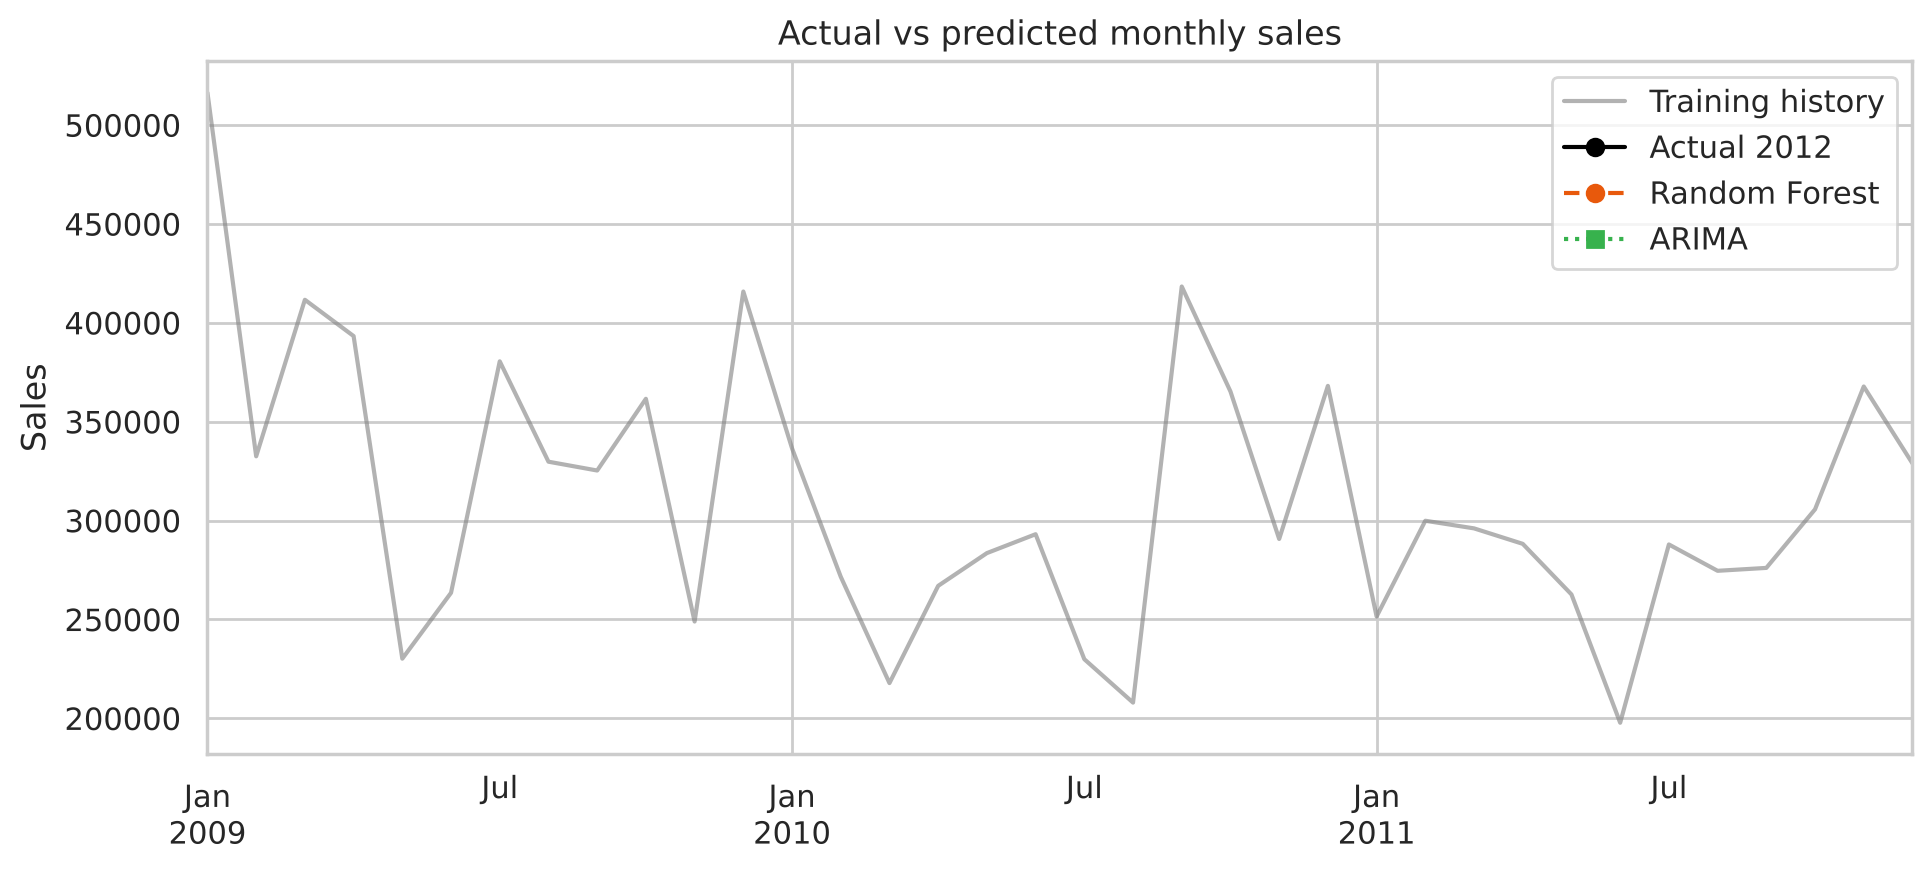

,Actual,Random Forest,ARIMA,RF error %,ARIMA error %
Order Date,,,,,
Jan 2012,"340,626.51","276,517.55","306,674.43",-18.8%,-10.0%
Feb 2012,"276,132.50","268,123.78","310,413.62",-2.9%,+12.4%
Mar 2012,"348,208.33","251,893.77","310,037.35",-27.7%,-11.0%
Apr 2012,"268,024.97","283,916.59","309,519.24",+5.9%,+15.5%
May 2012,"384,588.06","270,702.82","307,551.79",-29.6%,-20.0%
Jun 2012,"276,580.94","296,288.51","302,733.90",+7.1%,+9.5%
Jul 2012,"242,809.70","256,782.72","309,453.38",+5.8%,+27.4%
Aug 2012,"302,745.12","268,967.65","308,479.38",-11.2%,+1.9%
Sep 2012,"318,271.57","328,823.21","308,571.27",+3.3%,-3.0%


In [17]:
ARIMA_NAME = "ARIMA (1,0,1)(1,0,0,12)"
fig, ax = plt.subplots()
monthly.loc[:"2011-12"].plot(ax=ax, color="grey", alpha=0.6, label="Training history")
ax.plot(test.index, y_test, "o-", color="black", label="Actual 2012")
ax.plot(test.index, predictions["Random Forest"], "o--", color="#e8590c", label="Random Forest")
ax.plot(test.index, predictions[ARIMA_NAME], "s:", color="#37b24d", label="ARIMA")
ax.set(title="Actual vs predicted monthly sales", ylabel="Sales", xlabel="")
ax.legend()
plt.show()

comparison = pd.DataFrame({"Actual": y_test,
                           "Random Forest": predictions["Random Forest"],
                           "ARIMA": predictions[ARIMA_NAME]})
comparison["RF error %"] = ((comparison["Random Forest"] / comparison["Actual"]) - 1).map("{:+.1%}".format)
comparison["ARIMA error %"] = ((comparison["ARIMA"] / comparison["Actual"]) - 1).map("{:+.1%}".format)
comparison.index = comparison.index.strftime("%b %Y")
comparison

### Which features matter? (Random Forest)

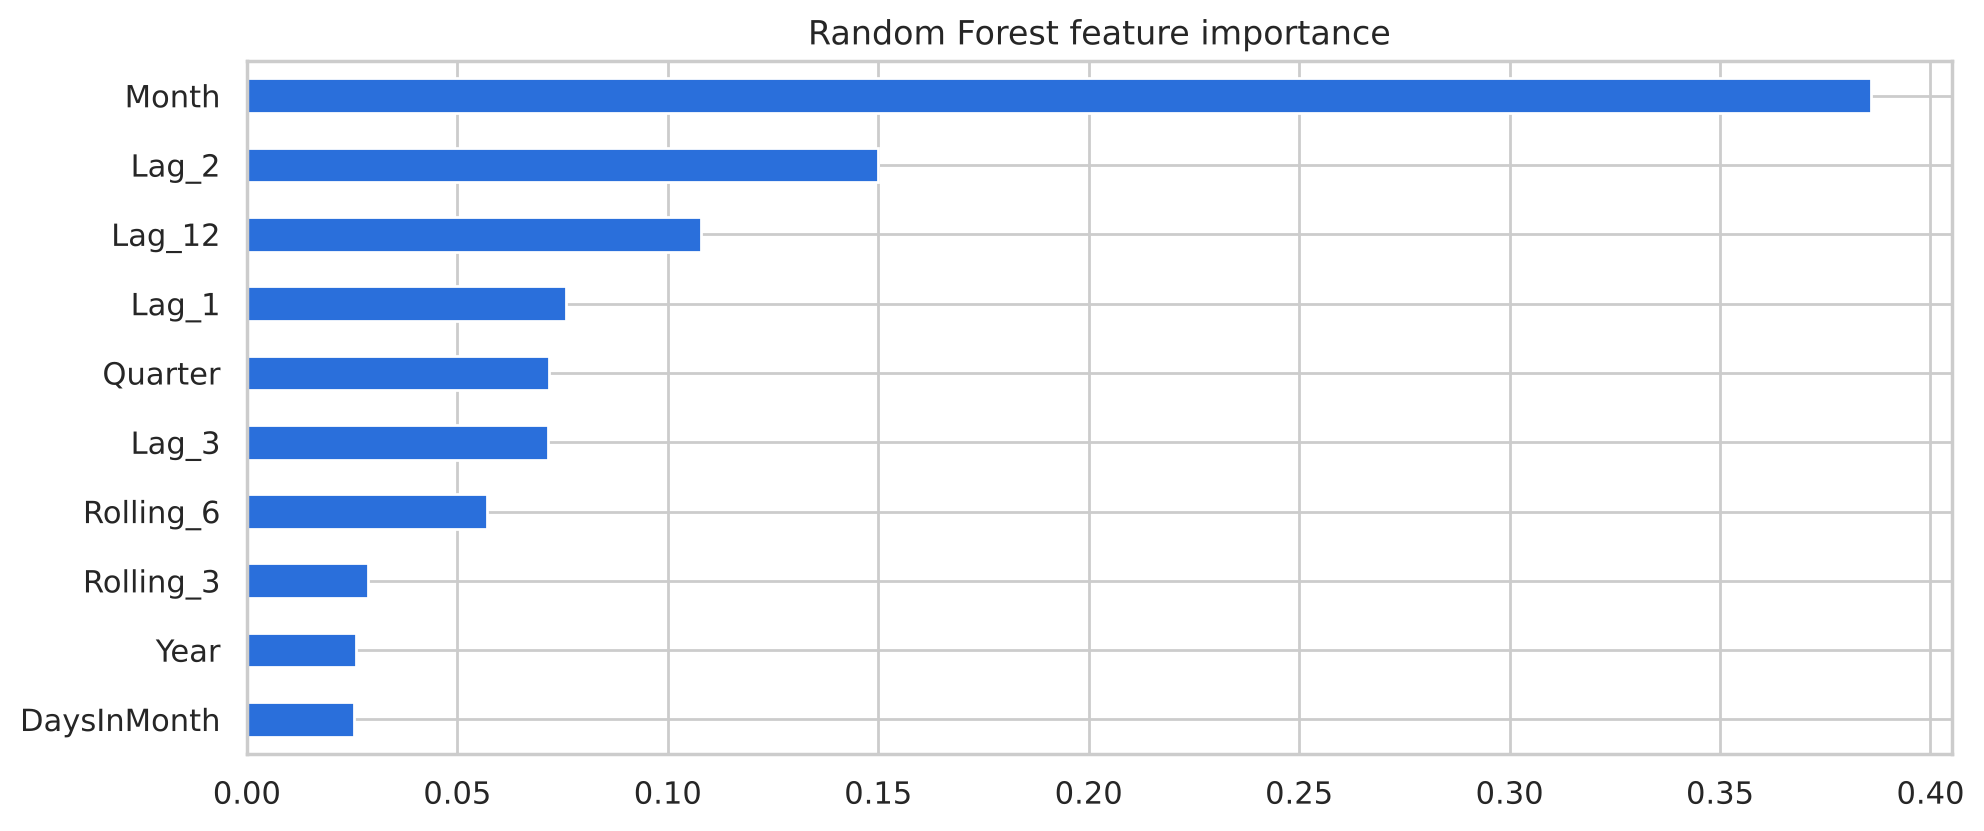

In [18]:
rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot(kind="barh", color="#2a6fdb")
plt.title("Random Forest feature importance")
plt.show()

## 8. Forecasting the future: next 6 months (Jan–Jun 2013)
I retrain both strong models on **all** the data. Random Forest forecasts step by step, with each predicted month becoming a lag input for the next one (recursive forecasting). ARIMA forecasts natively and also gives an uncertainty interval.

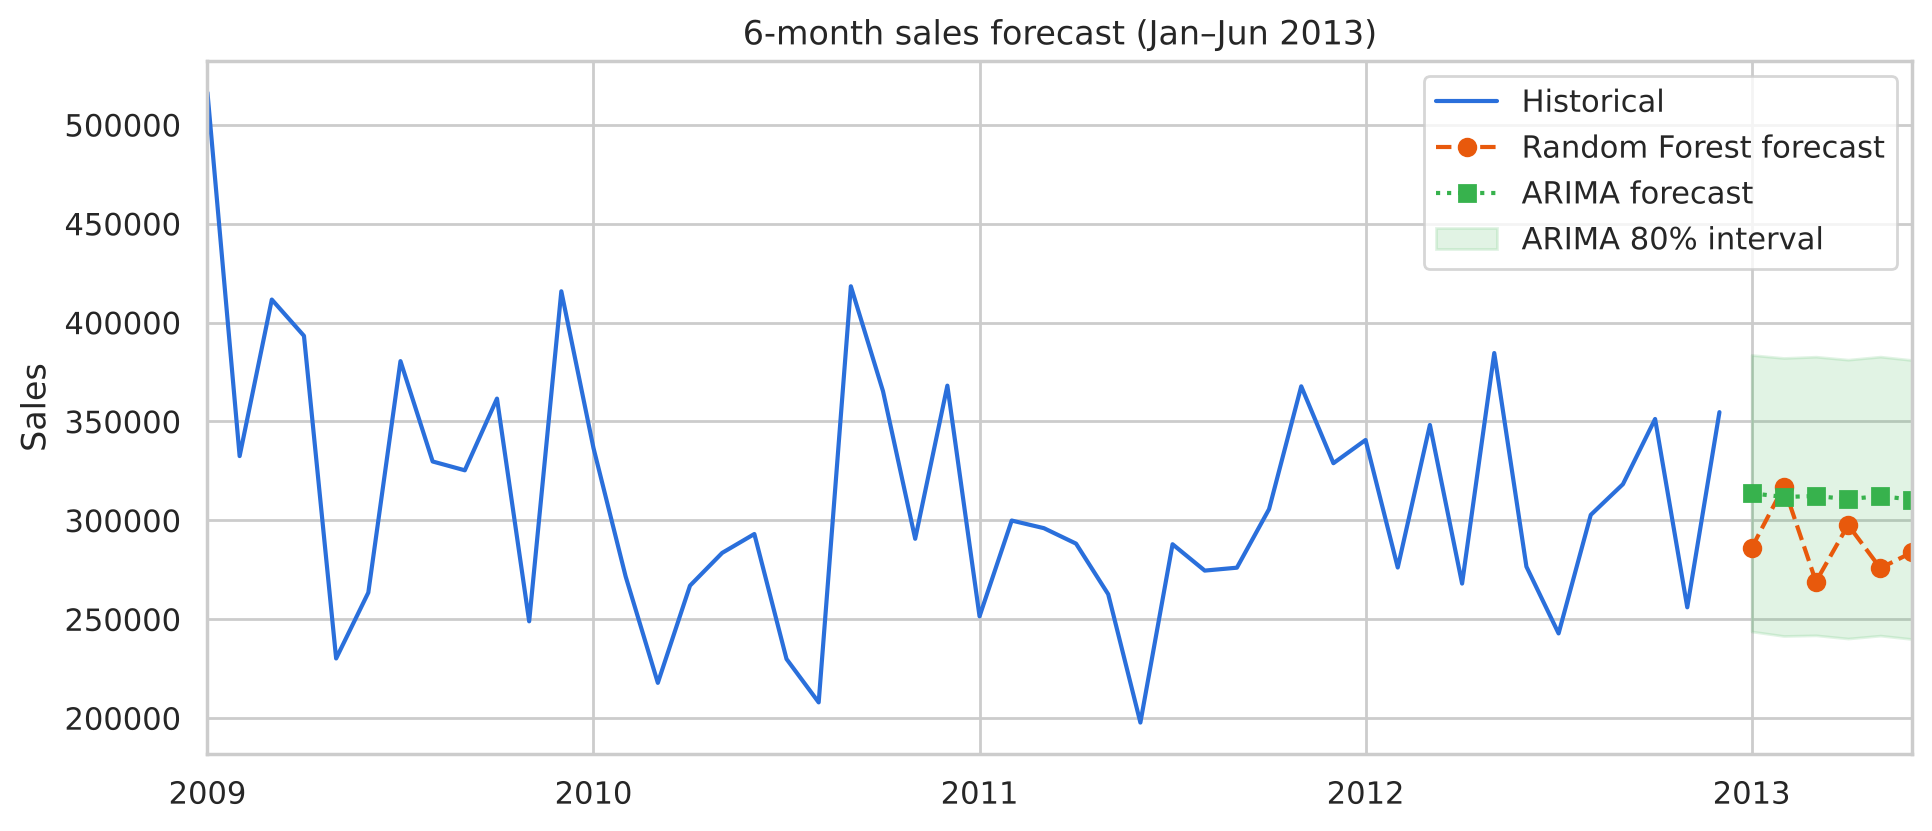

,Random Forest,ARIMA,ARIMA low (80%),ARIMA high (80%),Average of both
Order Date,,,,,
Jan 2013,"286,019.35","313,692.44","243,792.30","383,592.58","299,855.89"
Feb 2013,"317,092.99","311,802.34","241,511.62","382,093.06","314,447.66"
Mar 2013,"268,983.60","312,291.11","241,846.44","382,735.77","290,637.36"
Apr 2013,"297,661.48","310,729.09","240,223.61","381,234.57","304,195.29"
May 2013,"275,830.51","312,233.80","241,704.27","382,763.33","294,032.16"
Jun 2013,"283,908.40","310,479.65","239,940.61","381,018.69","297,194.02"


In [19]:
def recursive_forecast(model, history: pd.Series, steps: int) -> pd.Series:
    hist = history.copy()
    for _ in range(steps):
        next_date = hist.index[-1] + pd.offsets.MonthBegin(1)
        hist.loc[next_date] = np.nan
        row = make_features(hist).iloc[[-1]][FEATURES]
        hist.loc[next_date] = model.predict(row)[0]
    return hist.iloc[-steps:]

final_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)
final_model.fit(features[FEATURES], features["Sales"])
rf_future = recursive_forecast(final_model, monthly, steps=6)

final_arima = ARIMA(monthly, order=(1, 0, 1), seasonal_order=(1, 0, 0, 12)).fit()
arima_future = final_arima.get_forecast(6)
arima_ci = arima_future.conf_int(alpha=0.2)  # 80% interval

ax = monthly.plot(color="#2a6fdb", label="Historical")
rf_future.plot(ax=ax, style="o--", color="#e8590c", label="Random Forest forecast")
arima_future.predicted_mean.plot(ax=ax, style="s:", color="#37b24d", label="ARIMA forecast")
ax.fill_between(arima_ci.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="#37b24d", alpha=0.15,
                label="ARIMA 80% interval")
ax.set(title="6-month sales forecast (Jan–Jun 2013)", ylabel="Sales", xlabel="")
ax.legend()
plt.show()

forecast_table = pd.DataFrame({"Random Forest": rf_future.values,
                               "ARIMA": arima_future.predicted_mean.values,
                               "ARIMA low (80%)": arima_ci.iloc[:, 0].values,
                               "ARIMA high (80%)": arima_ci.iloc[:, 1].values},
                              index=rf_future.index.strftime("%b %Y"))
forecast_table["Average of both"] = forecast_table[["Random Forest", "ARIMA"]].mean(axis=1)
forecast_table

## 9. Conclusion
- I cleaned and explored four years of real order data, then turned it into a monthly series with calendar, lag and rolling features.
- **ARIMA** (MAE ≈ 39.6k, MAPE ≈ 13%) and **Random Forest** (MAE ≈ 41.8k, MAPE ≈ 13%) clearly beat the naive baseline on the unseen 2012 data, cutting MAE by roughly 40%. Linear Regression overfit the small training set.
- The most useful signals are recent sales levels (lags and rolling means) and the same month last year.
- **Limitations:** 48 months is a short history, and a few very large orders make monthly totals noisy. More years of data, or forecasting per category or region, would make the model more reliable.
- **Next steps:** forecast by product category, add holiday or promotion flags, and try Prophet or gradient boosting.